In [1]:
from pathlib import Path
import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import ConcatDataset, Subset, DataLoader
from torchvision import datasets, transforms
from skimage.metrics import structural_similarity as ssim

SEED, BATCH, LATENT, EPOCHS, LR = 42, 128, 64, 15, 1e-3
LAMBDA = 1e-4  # kekuatan regularisasi L1; boleh dituning memakai validation set
OUT = Path('outputs/sparse_ae')
OUT.mkdir(parents=True, exist_ok=True)
SPLIT_FILE = Path('fashion_mnist_split_seed42.npz')
MODEL_FILE = OUT / 'best_sparse_ae.pt'

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [2]:
transform = transforms.ToTensor()
full = ConcatDataset([
    datasets.FashionMNIST('data', train=True, download=True, transform=transform),
    datasets.FashionMNIST('data', train=False, download=True, transform=transform),
])

# Gunakan split file yang sama dengan Vanilla AE, jika sudah tersedia.
if SPLIT_FILE.exists():
    s = np.load(SPLIT_FILE)
    train_idx, val_idx, test_idx = s['train_idx'], s['val_idx'], s['test_idx']
else:
    idx = torch.randperm(len(full), generator=torch.Generator().manual_seed(SEED)).numpy()
    train_idx, val_idx, test_idx = idx[:56000], idx[56000:63000], idx[63000:]
    np.savez_compressed(SPLIT_FILE, train_idx=train_idx, val_idx=val_idx, test_idx=test_idx)

assert (len(train_idx), len(val_idx), len(test_idx)) == (56000, 7000, 7000)
assert len(np.unique(np.r_[train_idx, val_idx, test_idx])) == len(full)
train_set, val_set, test_set = [Subset(full, ids.tolist()) for ids in
                                (train_idx, val_idx, test_idx)]
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_set, batch_size=BATCH, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH, shuffle=False)
print('Train / Val / Test:', len(train_set), len(val_set), len(test_set))

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 165kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.16MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.6MB/s]


Train / Val / Test: 56000 7000 7000


In [3]:
class SparseAE(nn.Module):
    def __init__(self):
        super().__init__()
        # Identik dengan Vanilla AE agar komparasi terkontrol.
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
                                     nn.Linear(256, LATENT), nn.ReLU())
        self.decoder = nn.Sequential(nn.Linear(LATENT, 256), nn.ReLU(),
                                     nn.Linear(256, 784), nn.Sigmoid())

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z).reshape(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z), z

model = SparseAE().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
num_params = sum(p.numel() for p in model.parameters())
print(f'Jumlah parameter: {num_params:,}')

Jumlah parameter: 435,536


In [4]:
def sync():
    if device.type == 'cuda':
        torch.cuda.synchronize()
    elif device.type == 'mps':
        torch.mps.synchronize()

def run_epoch(loader, training=False):
    model.train(training)
    total_mse, total_l1, n = 0.0, 0.0, 0
    with torch.set_grad_enabled(training):
        for x, _ in loader:
            x = x.to(device)
            if training:
                optimizer.zero_grad()
            recon, z = model(x)
            mse = F.mse_loss(recon, x)
            l1 = z.abs().sum(dim=1).mean()  # ||z||_1 dirata-rata per gambar
            loss = mse + LAMBDA * l1
            if training:
                loss.backward()
                optimizer.step()
            total_mse += mse.item() * len(x)
            total_l1 += l1.item() * len(x)
            n += len(x)
    mse, l1 = total_mse/n, total_l1/n
    return mse, l1, mse + LAMBDA*l1

history, best_val, best_epoch = [], float('inf'), 0
for epoch in range(1, EPOCHS + 1):
    sync()
    start = time.perf_counter()
    train_mse, train_l1, train_total = run_epoch(train_loader, training=True)
    sync()
    seconds = time.perf_counter() - start
    val_mse, val_l1, val_total = run_epoch(val_loader)
    history.append({'epoch': epoch, 'train_mse': train_mse,
                    'val_mse': val_mse, 'train_l1': train_l1,
                    'val_l1': val_l1, 'train_total': train_total,
                    'val_total': val_total, 'training_time_s': seconds})
    if val_total < best_val:
        best_val, best_epoch = val_total, epoch
        torch.save(model.state_dict(), MODEL_FILE)
    print(f'Epoch {epoch:02} | Train MSE {train_mse:.5f} | Val MSE {val_mse:.5f}'
          f' | Val Total {val_total:.5f} | {seconds:.1f}s')

history_df = pd.DataFrame(history)
history_df.to_csv(OUT / 'sparse_ae_history.csv', index=False)
model.load_state_dict(torch.load(MODEL_FILE, map_location=device, weights_only=True))
model.eval()
print('Best epoch:', best_epoch)

Epoch 01 | Train MSE 0.03522 | Val MSE 0.02032 | Val Total 0.02218 | 7.9s
Epoch 02 | Train MSE 0.01820 | Val MSE 0.01701 | Val Total 0.01861 | 6.3s
Epoch 03 | Train MSE 0.01588 | Val MSE 0.01526 | Val Total 0.01678 | 7.8s
Epoch 04 | Train MSE 0.01456 | Val MSE 0.01436 | Val Total 0.01575 | 7.5s
Epoch 05 | Train MSE 0.01376 | Val MSE 0.01381 | Val Total 0.01515 | 6.3s
Epoch 06 | Train MSE 0.01314 | Val MSE 0.01313 | Val Total 0.01442 | 7.2s
Epoch 07 | Train MSE 0.01265 | Val MSE 0.01273 | Val Total 0.01400 | 6.2s
Epoch 08 | Train MSE 0.01221 | Val MSE 0.01233 | Val Total 0.01356 | 6.8s
Epoch 09 | Train MSE 0.01185 | Val MSE 0.01208 | Val Total 0.01329 | 6.7s
Epoch 10 | Train MSE 0.01150 | Val MSE 0.01163 | Val Total 0.01280 | 6.2s
Epoch 11 | Train MSE 0.01120 | Val MSE 0.01144 | Val Total 0.01258 | 6.9s
Epoch 12 | Train MSE 0.01097 | Val MSE 0.01122 | Val Total 0.01232 | 6.2s
Epoch 13 | Train MSE 0.01077 | Val MSE 0.01103 | Val Total 0.01212 | 6.9s
Epoch 14 | Train MSE 0.01058 | Val MSE

In [5]:
errors, psnr_values, ssim_values = 0.0, [], []
active_latent, all_latent, latent_l1_sum = 0, 0, 0.0
with torch.inference_mode():
    for x, _ in test_loader:
        x = x.to(device)
        recon, z = model(x)
        errors += F.mse_loss(recon, x, reduction='sum').item()
        per_image_mse = (recon - x).square().flatten(1).mean(dim=1)
        psnr_values.extend((10 * torch.log10(1 / per_image_mse.clamp_min(1e-12))).cpu().tolist())
        x_np, recon_np = x.cpu().numpy(), recon.cpu().numpy()
        ssim_values.extend(ssim(a[0], b[0], data_range=1.0)
                           for a, b in zip(x_np, recon_np))
        active_latent += (z > 1e-3).sum().item()
        all_latent += z.numel()
        latent_l1_sum += z.abs().sum().item()

test_mse = errors / (len(test_set) * 28 * 28)
test_psnr = float(np.mean(psnr_values))
test_ssim = float(np.mean(ssim_values))
latent_zero_fraction = 1 - active_latent / all_latent
mean_latent_l1 = latent_l1_sum / len(test_set)

x64 = next(iter(test_loader))[0][:64].to(device)
with torch.inference_mode():
    for _ in range(10):
        model(x64)  # warmup
    timings = []
    for _ in range(30):
        sync()
        start = time.perf_counter()
        model(x64)
        sync()
        timings.append((time.perf_counter() - start) * 1000)
latency = float(np.mean(timings))
print(f'Test MSE  : {test_mse:.6f}')
print(f'Test PSNR : {test_psnr:.3f} dB')
print(f'Test SSIM : {test_ssim:.4f}')
print(f'Latent mendekati nol (< 1e-3): {latent_zero_fraction:.1%}')
print(f'Latency   : {latency:.3f} ± {np.std(timings):.3f} ms / batch 64')

Test MSE  : 0.010564
Test PSNR : 20.672 dB
Test SSIM : 0.7415
Latent mendekati nol (< 1e-3): 57.9%
Latency   : 0.215 ± 0.025 ms / batch 64


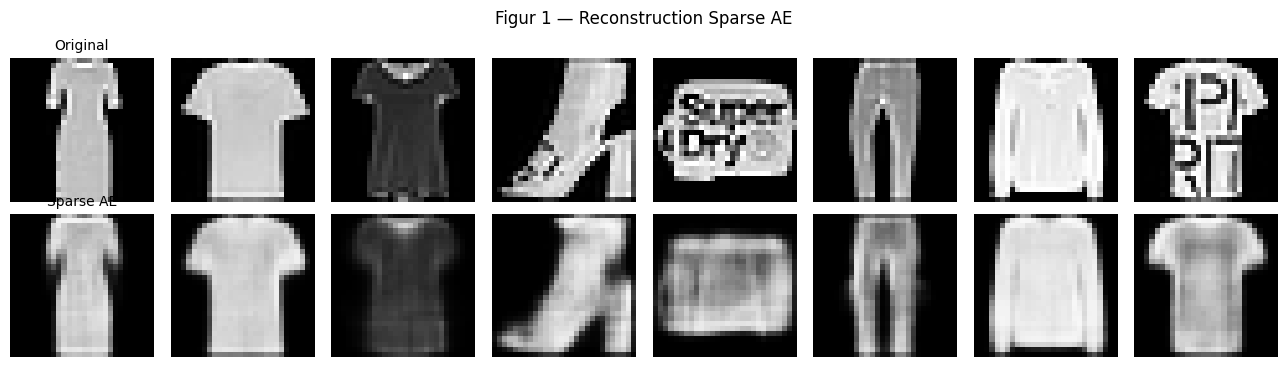

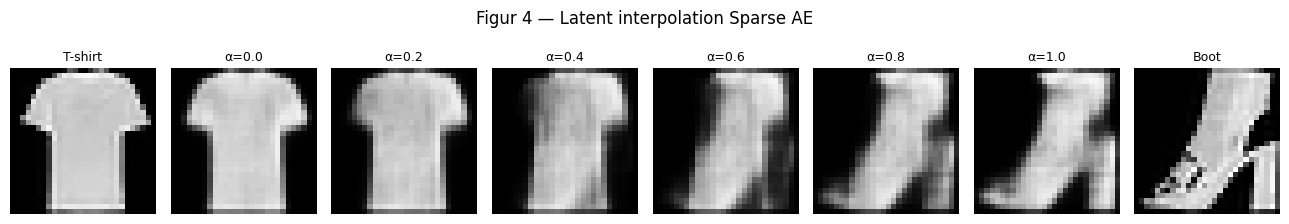

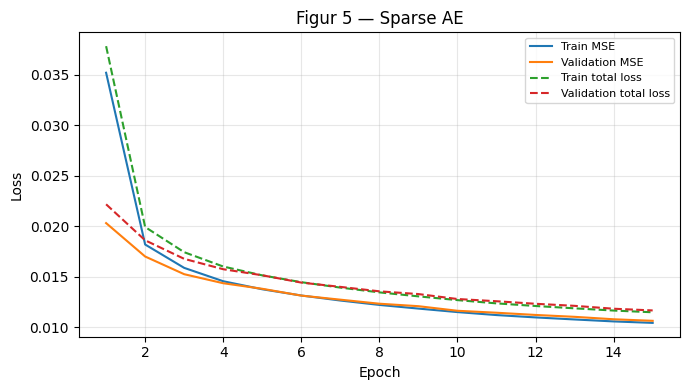

In [6]:
# Figur 1 — 8 gambar asli vs rekonstruksi Sparse AE
x8 = next(iter(test_loader))[0][:8].to(device)
with torch.inference_mode():
    recon8, _ = model(x8)
    recon8 = recon8.cpu()
fig, axes = plt.subplots(2, 8, figsize=(13, 3.7))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[1, i].imshow(recon8[i, 0], cmap='gray', vmin=0, vmax=1)
    for row in axes:
        row[i].axis('off')
axes[0, 0].set_title('Original', fontsize=10)
axes[1, 0].set_title('Sparse AE', fontsize=10)
fig.suptitle('Figur 1 — Reconstruction Sparse AE')
plt.tight_layout()
plt.savefig(OUT / 'figure1_sparse_ae_reconstruction.png', dpi=200)
plt.show()

# Figur 4 — Interpolasi kelas 0 (T-shirt) ke 9 (Ankle boot)
def sample_of_class(target):
    for x, label in test_set:
        if label == target:
            return x.unsqueeze(0).to(device)
    raise ValueError(f'Kelas {target} tidak ditemukan')

x_a, x_b = sample_of_class(0), sample_of_class(9)
alphas = np.linspace(0, 1, 6)
with torch.inference_mode():
    z_a, z_b = model.encode(x_a), model.encode(x_b)
    z = torch.cat([(1-float(a))*z_a + float(a)*z_b for a in alphas])
    images = model.decode(z).cpu()
fig, axes = plt.subplots(1, 8, figsize=(13, 2.4))
for i in range(8):
    img = x_a[0, 0].cpu() if i == 0 else x_b[0, 0].cpu() if i == 7 else images[i-1, 0]
    axes[i].imshow(img, cmap='gray', vmin=0, vmax=1)
    axes[i].set_title('T-shirt' if i == 0 else 'Boot' if i == 7 else f'α={alphas[i-1]:.1f}', fontsize=9)
    axes[i].axis('off')
fig.suptitle('Figur 4 — Latent interpolation Sparse AE')
plt.tight_layout()
plt.savefig(OUT / 'figure4_sparse_ae_interpolation.png', dpi=200)
plt.show()

# Figur 5 — MSE vs total loss (MSE + lambda*L1)
plt.figure(figsize=(7, 4))
plt.plot(history_df['epoch'], history_df['train_mse'], label='Train MSE')
plt.plot(history_df['epoch'], history_df['val_mse'], label='Validation MSE')
plt.plot(history_df['epoch'], history_df['train_total'], '--', label='Train total loss')
plt.plot(history_df['epoch'], history_df['val_total'], '--', label='Validation total loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('Figur 5 — Sparse AE')
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(OUT / 'figure5_sparse_ae_loss.png', dpi=200)
plt.show()

In [7]:
result = pd.DataFrame([{
    'model': 'Sparse AE', 'dataset': 'Fashion-MNIST', 'seed': SEED,
    'train_size': len(train_set), 'val_size': len(val_set), 'test_size': len(test_set),
    'latent_dim': LATENT, 'batch_size': BATCH, 'num_parameters': num_params,
    'best_epoch': best_epoch,
    'training_time_epoch_s_mean': history_df['training_time_s'].mean(),
    'inference_latency_batch64_ms': latency,
    'test_mse': test_mse, 'test_psnr_db': test_psnr, 'test_ssim': test_ssim,
    'fid': np.nan,  # N/A untuk Sparse AE dalam tabel PDF
    'device': str(device),
    'lambda_l1': LAMBDA, 'test_latent_zero_fraction': latent_zero_fraction,
    'test_mean_latent_l1': mean_latent_l1,
}])
result.to_csv(OUT / 'sparse_ae_metrics.csv', index=False)
print(result.T.to_string(header=False))

# Jika Vanilla AE sudah dijalankan, tampilkan komparasi otomatis.
vanilla_file = Path('outputs/vanilla_ae/vanilla_ae_metrics.csv')
if vanilla_file.exists():
    vanilla = pd.read_csv(vanilla_file)
    cols = ['model', 'test_mse', 'test_psnr_db', 'test_ssim',
            'training_time_epoch_s_mean', 'inference_latency_batch64_ms']
    comparison = pd.concat([vanilla[cols], result[cols]], ignore_index=True)
    comparison.to_csv(OUT / 'vanilla_vs_sparse_ae.csv', index=False)
    print('\nPerbandingan Vanilla AE vs Sparse AE:')
    print(comparison.to_string(index=False))
else:
    print('\nJalankan notebook Vanilla AE di folder kerja yang sama untuk komparasi otomatis.')
print('File output:', OUT.resolve())

model                             Sparse AE
dataset                       Fashion-MNIST
seed                                     42
train_size                            56000
val_size                               7000
test_size                              7000
latent_dim                               64
batch_size                              128
num_parameters                       435536
best_epoch                               15
training_time_epoch_s_mean         6.791574
inference_latency_batch64_ms       0.214632
test_mse                           0.010564
test_psnr_db                      20.671545
test_ssim                          0.741518
fid                                     NaN
device                                 cuda
lambda_l1                            0.0001
test_latent_zero_fraction          0.578953
test_mean_latent_l1               10.308416

Jalankan notebook Vanilla AE di folder kerja yang sama untuk komparasi otomatis.
File output: /content/outputs/sparse_a

In [11]:
from google.colab import drive
drive.mount('/content/drive')
!cp -r "/content/outputs/sparse_ae" "/content/drive/MyDrive/[CN] Colab Notebooks/[CV] Computer Vision/DCGANAE: All Experiments/Results"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
